# Printed Meat: Commercial Feasibility Lab
## tl;dr
**Illustrative assumptions, not company forecasts.** The base case sells 86,400 kg/year and earns $120,352 annual operating contribution at steady state, while its five-year NPV is approximately −$1.54m. Higher availability does not add base-case sales because demand binds. The upside case becomes capacity-constrained.

This companion reproduces the repository's economics and interprets the outputs. Source review and caveats: `research/04-evidence-audit.md` and `data/evidence_ledger.csv`.

## Context & Methods
The decision is whether to test a hypothetical US plant-based whole-cut foodservice business before committing capital. Ingredient biology and structuring method are separate. The German cultivated-product survey is contextual and does not calibrate this model.

### Key Assumptions
All financial and operational values are illustrative; constant USD; 5 years; no taxes, financing, terminal value, or depreciation. Working capital is recovered at the end. Simulation inputs are independent triangular distributions, not estimated probabilities. See the formula dictionary in `research/03-commercial-model.md`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'analysis').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'data/assumptions.json').is_file(), 'Run from repository root or notebooks/'
sys.path.insert(0, str(ROOT / 'analysis'))
from model import evaluate
from run_analysis import run
run()
config = json.loads((ROOT / 'data/assumptions.json').read_text())
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

Generated scenarios, annual cashflows, sensitivity, simulation and summary.


## Data
The model consumes only explicit assumptions. The source ledger describes reviewed public evidence and its permitted use; it is not a company operating dataset.

In [2]:
display(pd.read_csv(ROOT / 'data/evidence_ledger.csv')[['source_id','evidence_class','review_status']])
display(pd.DataFrame(config['cases']).loc[['capture_fraction','availability','quality_yield','invoice_price_kg','input_conversion_cost_kg','fixed_cost_year','initial_capital']])

,source_id,evidence_class,review_status
0,E01,Survey owner,reviewed_source_text
1,E02,Industry organization citing SPINS,reviewed_source_text
2,E03,Company reported,reviewed_source_text
3,E04,Company reported,reviewed_source_text
4,E05,Company reported,reviewed_source_text
5,E06,Regulator,reviewed_source_text
6,E07,Regulator,reviewed_source_text
7,E08,Regulator,reviewed_source_text
8,E09,Legislation,reviewed_source_text
9,E10,Issuer filing,reviewed_source_text


,downside,base,upside
capture_fraction,0.12,0.25,0.5
availability,0.45,0.65,0.85
quality_yield,0.82,0.9,0.95
invoice_price_kg,21,24,28
input_conversion_cost_kg,11,9,7.5
fixed_cost_year,550000,500000,450000
initial_capital,1400000,1200000,1000000


## Results
### 1. Reconcile demand, capacity, and operating economics
Cases change multiple assumptions together; differences are not causal effects of one variable.

,scenario,obtainable_demand_kg,capacity_kg,sold_kg,bottleneck,contribution_kg,operating_contribution_usd,npv_5y_usd
0,downside,41472.0,56678.4,41472.0,demand,1.31,-495863.87,-3368840.50
1,base,86400.0,89856.0,86400.0,demand,7.18,120352.00,-1538588.55
2,upside,172800.0,124032.0,124032.0,capacity,12.57,1108494.72,1257239.53


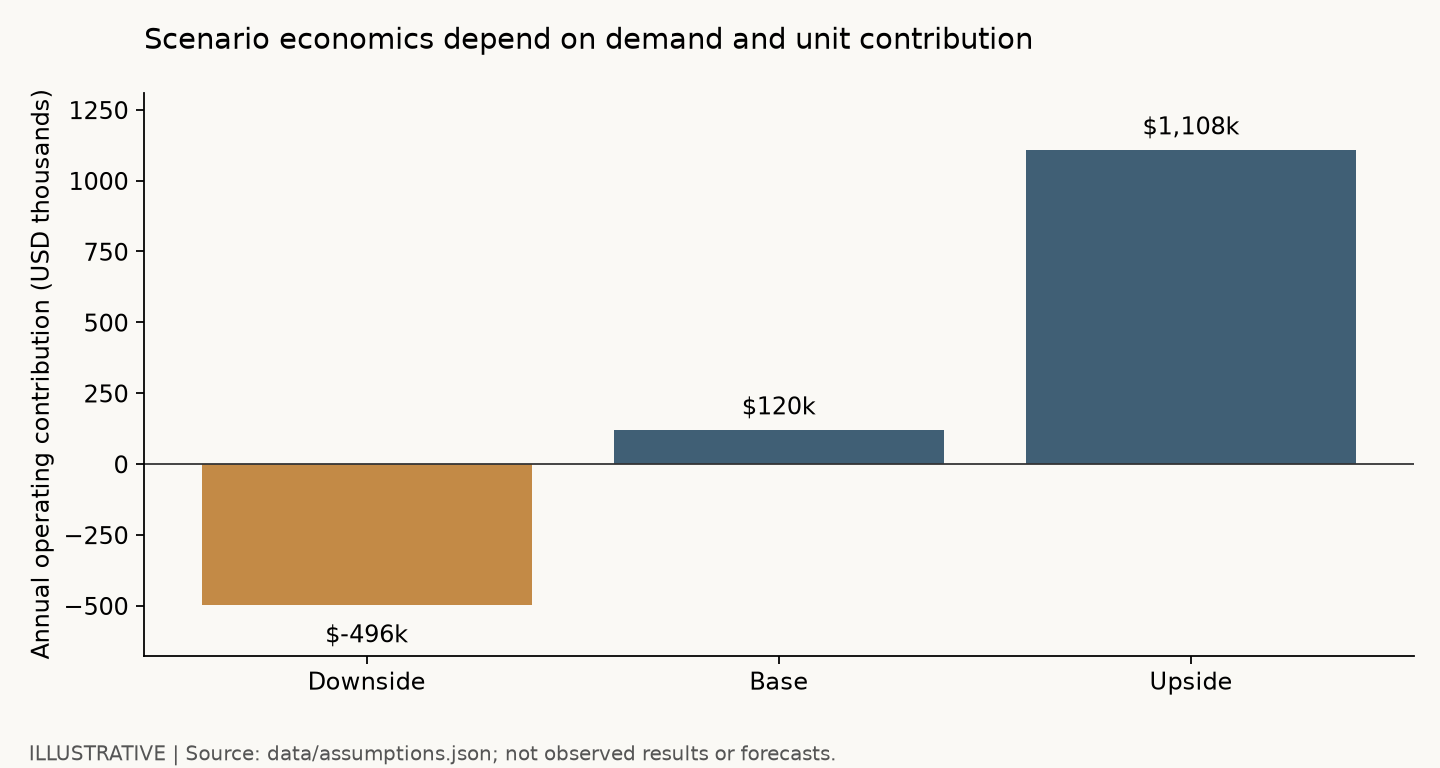

In [3]:
scenarios = pd.read_csv(ROOT / 'results/scenarios.csv')
display(scenarios[['scenario','obtainable_demand_kg','capacity_kg','sold_kg','bottleneck','contribution_kg','operating_contribution_usd','npv_5y_usd']].round(2))
from IPython.display import Image
display(Image(filename=str(ROOT / 'charts/scenario_operating_profit.png')))

The base case is demand-constrained: its 86,400 kg demand is below technical capacity. Buying additional capacity does not address the binding constraint. These are internal scenario outcomes, not observed sales.

### 2. Test price and availability
The heatmap changes invoice price before deductions and production availability. Flat regions indicate demand rather than output is limiting sales.

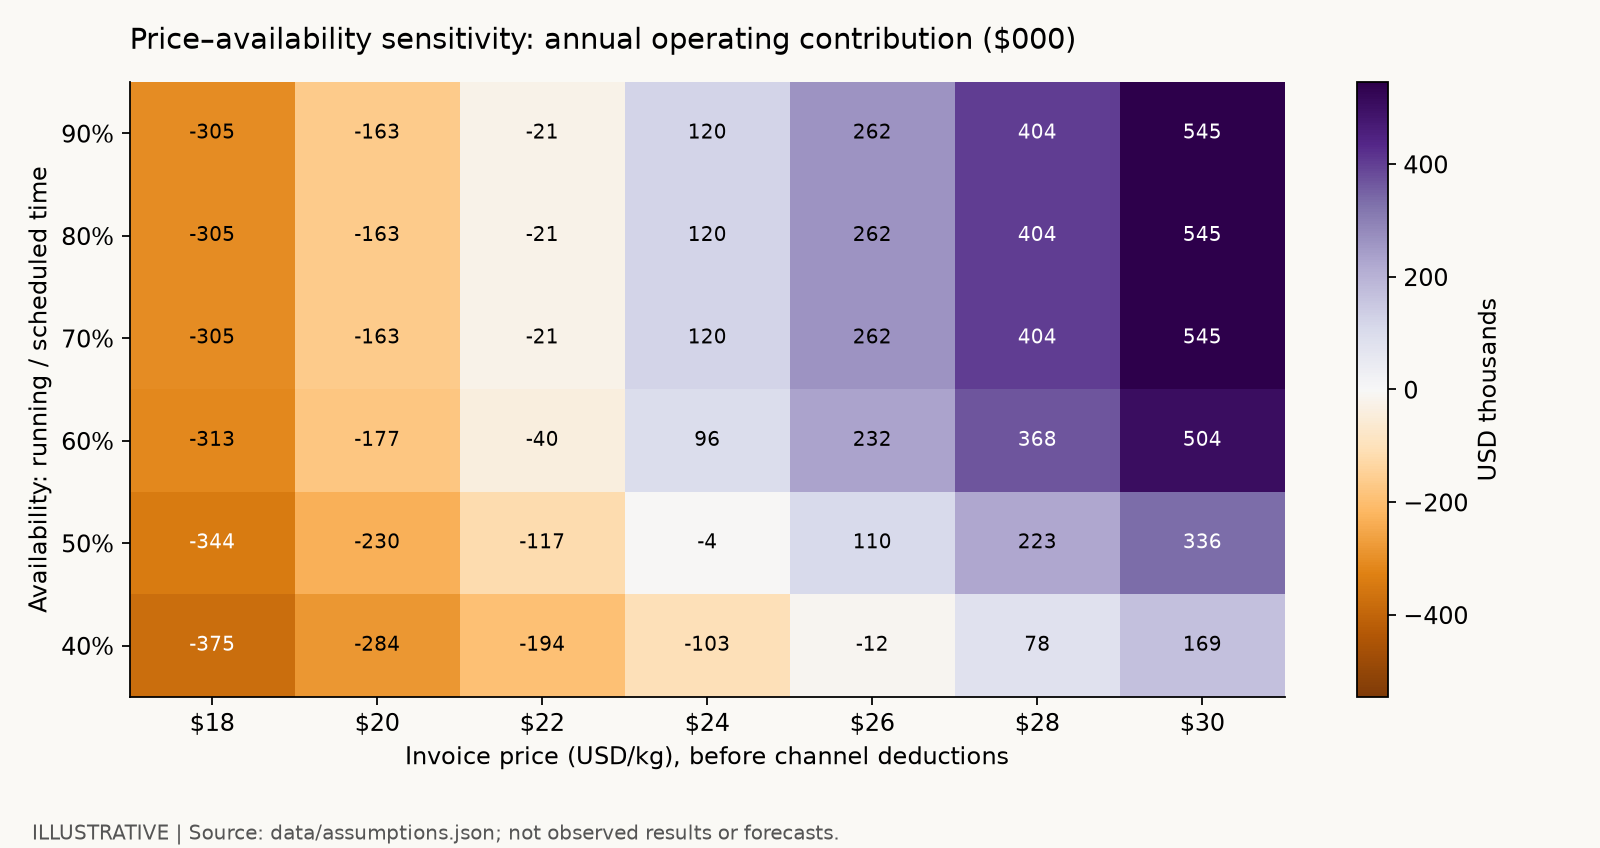

In [4]:
display(Image(filename=str(ROOT / 'charts/price_utilization.png')))

### 3. Explore uncertainty
The fixed seed and 10,000 draws make this experiment reproducible. Quantiles and draw frequencies are conditional on chosen distributions. Capture and price independence is a material limitation.

label                          Illustrative independent triangular input draw...
seed                                                                    20261020
draws                                                                      10000
operating_profit_p10_usd                                          -245677.786425
operating_profit_p50_usd                                             3090.293857
operating_profit_p90_usd                                           295531.348511
fraction_positive_operating                                                0.506
fraction_positive_npv                                                     0.0011
dtype: object

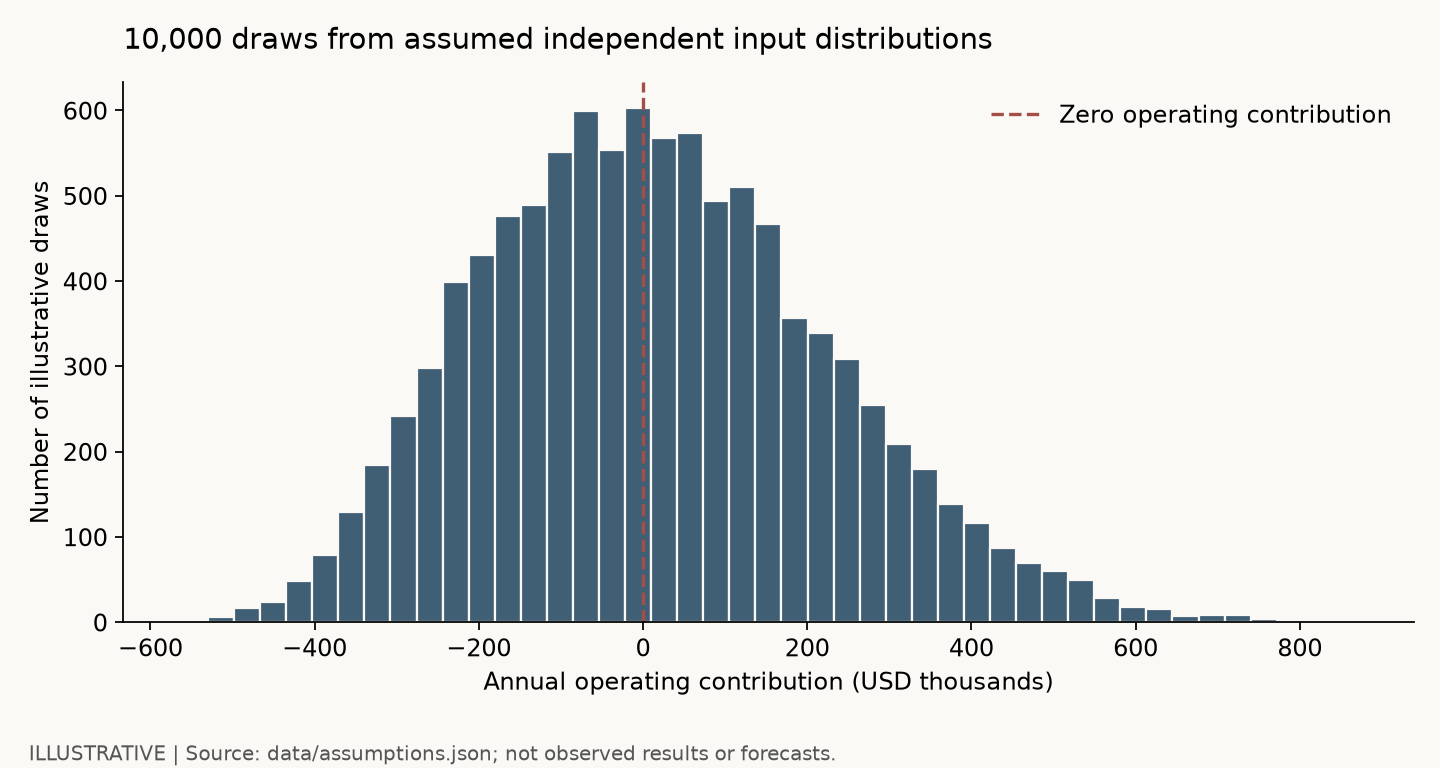

In [5]:
simulation = json.loads((ROOT / 'results/simulation_summary.json').read_text())
display(pd.Series(simulation))
display(Image(filename=str(ROOT / 'charts/simulated_profit.png')))

### 4. Inspect capital and cash timing
Annual operating contribution and project cash flow answer different questions. Initial capital occurs at year zero. The table below includes the operating ramp, maintenance capital and working-capital changes; final working capital is recovered.

In [6]:
cash = pd.read_csv(ROOT / 'results/annual_cashflows.csv')
display(cash.loc[cash.scenario == 'base'].round(0))
base = evaluate(config['cases']['base'])
assert abs(base['npv_5y_usd'] - (-config['cases']['base']['initial_capital'] + sum(y['free_cash_flow_usd'] / (1 + config['cases']['base']['discount_rate']) ** y['year'] for y in base['years']))) < 1e-6
assert base['sold_kg'] <= min(base['capacity_kg'], base['obtainable_demand_kg'])

,scenario,year,ramp,sold_kg,revenue_usd,operating_contribution_usd,working_capital_usd,free_cash_flow_usd,cumulative_cash_usd
5,base,1,0.0,34560.0,680141.0,-251859.0,83853.0,-365712.0,-1565712.0
6,base,2,1.0,51840.0,1020211.0,-127789.0,125779.0,-199715.0,-1765427.0
7,base,3,1.0,69120.0,1360282.0,-3718.0,167706.0,-75645.0,-1841072.0
8,base,4,1.0,86400.0,1700352.0,120352.0,209632.0,48426.0,-1792647.0
9,base,5,1.0,86400.0,1700352.0,120352.0,209632.0,299984.0,-1492662.0


## Takeaways
The model demonstrates why demand, saleable output, contribution, and capital recovery should be reconciled before recommending scale. Its base configuration has positive steady-state operating contribution and negative five-year NPV. The simulation is an assumption exercise and does not validate the business.

Next evidence: written net-price and production quotes, full-shift line trials, a product-specific regulatory review, and mature paid-reorder cohorts. The experiment plan and stage gates are in `research/05-consumer-experiments.md` and `research/06-strategy-kpis.md`.